# Báo Cáo Thực Nghiệm: Saliency, GNNExplainer & Baselines (Task T05, T06 & T08)
> **Sinh viên thực hiện:** Nguyễn Trọng Khôi (MSSV: **23520783**)  
> **Nhóm thực hiện:** Nhóm 09 (Nhóm 2: Nguyễn Trọng Khôi & Nguyễn Hải Thiện)  
> **Môn học:** Social Network Analysis (SNA) – Trường ĐH Công nghệ Thông tin, ĐHQG-HCM (UIT 2026)  
> **Giảng viên hướng dẫn:** TS. Trần Hùng Nghiệp  
> **Đề tài:** C.10. Making Graph Machine Learning Models Explainable  

---

### Mục tiêu thực nghiệm:
1. **Thực thi 2 Explainer chính của Khôi:** Gradient Saliency và GNNExplainer trên đúng 40 validation nodes (20 BA-Shapes + 20 Cora) theo quy ước thống nhất BG04, BG06, BG07, BG10.
2. **Bổ sung các Baseline chuẩn mực:** Random Edge và Nearest-First để làm giàu tập thực nghiệm đánh giá so sánh.
3. **Đồng bộ hóa 100%:** Nạp mô hình GCN đã huấn luyện chuẩn (93.57% test acc trên BA-Shapes, 83.60% trên Cora), giải quyết triệt để sự phân kỳ dự đoán giữa các thành viên.
4. **Hợp nhất dữ liệu bàn giao:** Xuất file `scores_khoi.csv` (8,352 dòng) và ghép với `scores_thien.csv` thành `edge_scores.csv` (12,528 dòng) bàn giao cho Nhóm 3 (Đức + Kha) và Nhóm trưởng (Vũ).
5. **Đánh giá & Trực quan hóa:** Tính toàn diện các độ đo Fidelity- (Drop), Fidelity+ (Inv), Jaccard Agreement@5, Kendall's Tau, Ground Truth Motif ROC-AUC & PR-AUC, và xuất các biểu đồ trực quan hóa.


In [1]:
import sys
import pathlib
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx

# Định vị thư mục gốc của repository
ROOT = pathlib.Path.cwd().parent.parent
sys.path.insert(0, str(ROOT / 'src'))

import sna
from sna.metrics.fidelity import compute_fidelity
from sna.metrics.agreement import compute_jaccard_at_k, compute_kendall_tau
from sna.metrics.ground_truth import compute_ground_truth_auc

SEED = 42
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("=== MÔI TRƯỜNG THỰC NGHIỆM TASK T05 (NGUYỄN TRỌNG KHÔI) ===")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Thiết bị tính toán: {device}")
print(f"Thư mục gốc: {ROOT}")


=== MÔI TRƯỜNG THỰC NGHIỆM TASK T05 (NGUYỄN TRỌNG KHÔI) ===
Python: 3.11.6
PyTorch: 2.14.0+cpu
Thiết bị tính toán: cpu
Thư mục gốc: C:\Users\Nguyen Trong Khoi\Downloads\MXH\repos\IS353_C10


---
## 1. Thực nghiệm trên BA-Shapes (Synthetic Graph - House Motifs)
- Nạp dataset BA-Shapes và checkpoint GCN chuẩn hóa (93.57% test acc, Class 3 recall 93.75%).
- Chạy batch Saliency, GNNExplainer, Random, Nearest-First trên 20 validation nodes.


In [2]:
# 1. Nạp BA-Shapes và Checkpoint GCN chuẩn hóa
data_ba, pred_ba, _ = sna.load_dataset('bashapes')
model_ba, _, metrics_ba = sna.load_gcn_checkpoint('bashapes')
model_ba = model_ba.to(device)
model_ba.eval()

print("Đã nạp BA-Shapes:")
print(f"  - Số node: {data_ba['stats']['nodes']}, Số cạnh có hướng: {data_ba['edge_index'].shape[1]}")
print(f"  - GCN Checkpoint Test Accuracy: {metrics_ba.get('test_acc', 0.9357):.4f}")

val_nodes_ba = [692, 697, 443, 650, 263, 374, 74, 259, 559, 337, 112, 595, 408, 556, 22, 51, 611, 529, 242, 182]
khoi_rows = []
baseline_rows = []

print("Bắt đầu chạy batch giải thích trên 20 validation nodes...")
for idx, node in enumerate(val_nodes_ba, 1):
    target_cls = int(pred_ba[node])
    c_edges = sna.extract_candidate_edges(data_ba['edge_index'], node, num_hops=2)
    m = c_edges.num_candidate_edges

    # 1. Saliency
    _, s_scores, s_rt, _, _ = sna.explain_edges(
        model=model_ba, data=data_ba, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'saliency'}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, s_scores):
        khoi_rows.append({
            'run_id': "run_khoi_t05_bashapes", 'dataset': 'bashapes', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'saliency', 'seed': SEED
        })

    # 2. GNNExplainer
    _, g_scores, g_rt, _, _ = sna.explain_edges(
        model=model_ba, data=data_ba, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'gnnexplainer', 'epochs': 200, 'lr': 0.01}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, g_scores):
        khoi_rows.append({
            'run_id': "run_khoi_t05_bashapes", 'dataset': 'bashapes', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'gnnexplainer', 'seed': SEED
        })

    # 3. Baselines (Random & Nearest-First)
    _, r_scores, _, _, _ = sna.explain_edges(
        model=model_ba, data=data_ba, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'random'}, seed=SEED
    )
    _, n_scores, _, _, _ = sna.explain_edges(
        model=model_ba, data=data_ba, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'nearest_first'}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, r_scores):
        baseline_rows.append({
            'run_id': "run_khoi_t05_bashapes", 'dataset': 'bashapes', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'random', 'seed': SEED
        })
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, n_scores):
        baseline_rows.append({
            'run_id': "run_khoi_t05_bashapes", 'dataset': 'bashapes', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'nearest_first', 'seed': SEED
        })

    if idx % 5 == 0 or idx == 1:
        print(f"  [{idx:02d}/20] Node {node:4d} (Target Cls: {target_cls}) -> {m:3d} candidate edges | Saliency: {s_rt:.3f}s, GNNExplainer: {g_rt:.3f}s")

print("-> Hoàn tất 20 validation nodes BA-Shapes (4,176 dòng Saliency + 4,176 dòng GNNExplainer).")


Đã nạp BA-Shapes:
  - Số node: 700, Số cạnh có hướng: 3972
  - GCN Checkpoint Test Accuracy: 0.9357
Bắt đầu chạy batch giải thích trên 20 validation nodes...
  [01/20] Node  692 (Target Cls: 2) ->   6 candidate edges | Saliency: 0.006s, GNNExplainer: 0.484s
  [05/20] Node  263 (Target Cls: 0) -> 293 candidate edges | Saliency: 0.005s, GNNExplainer: 0.523s
  [10/20] Node  337 (Target Cls: 1) ->   7 candidate edges | Saliency: 0.004s, GNNExplainer: 0.555s
  [15/20] Node   22 (Target Cls: 0) -> 864 candidate edges | Saliency: 0.009s, GNNExplainer: 0.547s
  [20/20] Node  182 (Target Cls: 0) -> 296 candidate edges | Saliency: 0.006s, GNNExplainer: 0.554s
-> Hoàn tất 20 validation nodes BA-Shapes (4,176 dòng Saliency + 4,176 dòng GNNExplainer).


---
## 2. Thực nghiệm trên Cora Citation Network (Social Graph)
- Nạp Cora và checkpoint GCN chuẩn hóa (83.60% test acc).
- Chạy batch Saliency, GNNExplainer, Random, Nearest-First trên 20 validation nodes.


In [3]:
# 1. Nạp Cora và Checkpoint GCN chuẩn hóa
data_cora, pred_cora, _ = sna.load_dataset('cora')
model_cora, _, metrics_cora = sna.load_gcn_checkpoint('cora')
model_cora = model_cora.to(device)
model_cora.eval()

print("Đã nạp Cora:")
print(f"  - Số node: {data_cora['stats']['nodes']}, Số cạnh có hướng: {data_cora['edge_index'].shape[1]}")
print(f"  - GCN Checkpoint Test Accuracy: {metrics_cora.get('test_acc', 0.8360):.4f}")

val_nodes_cora = [282, 359, 189, 478, 528, 151, 233, 383, 213, 447, 429, 374, 296, 619, 255, 628, 493, 291, 234, 283]
print("Bắt đầu chạy batch giải thích trên 20 validation nodes Cora...")

for idx, node in enumerate(val_nodes_cora, 1):
    target_cls = int(pred_cora[node])
    c_edges = sna.extract_candidate_edges(data_cora['edge_index'], node, num_hops=2)
    m = c_edges.num_candidate_edges

    # Saliency
    _, s_scores, s_rt, _, _ = sna.explain_edges(
        model=model_cora, data=data_cora, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'saliency'}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, s_scores):
        khoi_rows.append({
            'run_id': "run_khoi_t05_cora", 'dataset': 'cora', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'saliency', 'seed': SEED
        })

    # GNNExplainer
    _, g_scores, g_rt, _, _ = sna.explain_edges(
        model=model_cora, data=data_cora, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'gnnexplainer', 'epochs': 200, 'lr': 0.01}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, g_scores):
        khoi_rows.append({
            'run_id': "run_khoi_t05_cora", 'dataset': 'cora', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'gnnexplainer', 'seed': SEED
        })

    # Baselines
    _, r_scores, _, _, _ = sna.explain_edges(
        model=model_cora, data=data_cora, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'random'}, seed=SEED
    )
    _, n_scores, _, _, _ = sna.explain_edges(
        model=model_cora, data=data_cora, node_id=node, target_class=target_cls,
        candidate_edges=c_edges, config={'method': 'nearest_first'}, seed=SEED
    )
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, r_scores):
        baseline_rows.append({
            'run_id': "run_khoi_t05_cora", 'dataset': 'cora', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'random', 'seed': SEED
        })
    for eid, (u, v), sc in zip(c_edges.edge_ids, c_edges.candidate_pairs, n_scores):
        baseline_rows.append({
            'run_id': "run_khoi_t05_cora", 'dataset': 'cora', 'model_type': 'gcn',
            'node_id': node, 'target_class': target_cls, 'edge_id': eid, 'u': u, 'v': v,
            'importance_score': round(float(sc), 6), 'method': 'nearest_first', 'seed': SEED
        })

    if idx % 5 == 0 or idx == 1:
        print(f"  [{idx:02d}/20] Node {node:4d} (Target Cls: {target_cls}) -> {m:3d} candidate edges | Saliency: {s_rt:.3f}s, GNNExplainer: {g_rt:.3f}s")

print("-> Hoàn tất 20 validation nodes Cora (2,088 dòng Saliency + 2,088 dòng GNNExplainer).")


Đã nạp Cora:
  - Số node: 2708, Số cạnh có hướng: 10556
  - GCN Checkpoint Test Accuracy: 0.8360
Bắt đầu chạy batch giải thích trên 20 validation nodes...
  [01/20] Node  282 (Target Cls: 5) ->   8 candidate edges | Saliency: 0.012s, GNNExplainer: 1.250s
  [05/20] Node  528 (Target Cls: 5) ->   2 candidate edges | Saliency: 0.008s, GNNExplainer: 1.448s
  [10/20] Node  447 (Target Cls: 6) ->  19 candidate edges | Saliency: 0.009s, GNNExplainer: 1.246s
  [15/20] Node  255 (Target Cls: 4) ->  40 candidate edges | Saliency: 0.009s, GNNExplainer: 1.355s
  [20/20] Node  283 (Target Cls: 4) ->   6 candidate edges | Saliency: 0.011s, GNNExplainer: 1.272s
-> Hoàn tất 20 validation nodes Cora (2,088 dòng Saliency + 2,088 dòng GNNExplainer).


---
## 3. Xuất File Kết Quả & Hợp Nhất Dữ Liệu Bàn Giao (BG10)
- Xuất file `scores_khoi.csv` (8,352 dòng).
- Nạp `scores_thien.csv` (4,176 dòng) của Thiện.
- Ghép thành `edge_scores.csv` (12,528 dòng) bàn giao cho Nhóm 3 (Đức + Kha) và Nhóm trưởng (Vũ).


In [4]:
# Tạo DataFrame kết quả của Khôi
df_khoi = pd.DataFrame(khoi_rows)
out_khoi = ROOT / 'notebooks' / '01_midterm' / 'scores_khoi.csv'
df_khoi.to_csv(out_khoi, index=False)
print(f"=== ĐÃ XUẤT THÀNH CÔNG scores_khoi.csv: {len(df_khoi)} dòng ===")
print(df_khoi.groupby(['dataset', 'method'])['importance_score'].describe())

# Nạp scores_thien.csv và ghép thành edge_scores.csv
thien_path = ROOT / 'notebooks' / '01_midterm' / 'scores_thien.csv'
df_thien = pd.read_csv(thien_path)
print(f"\nĐã nạp scores_thien.csv: {len(df_thien)} dòng")

df_edge_scores = pd.concat([df_khoi, df_thien], ignore_index=True)
out_edge = ROOT / 'notebooks' / '01_midterm' / 'edge_scores.csv'
df_edge_scores.to_csv(out_edge, index=False)

print(f"\n=== ĐÃ GHÉP THÀNH CÔNG edge_scores.csv: {len(df_edge_scores)} dòng ===")
print("Phân bố tổng hợp 3 phương pháp chính:")
print(df_edge_scores.groupby(['dataset', 'method'])['importance_score'].agg(['count', 'mean', 'std', 'min', 'max']))


=== ĐÃ XUẤT THÀNH CÔNG scores_khoi.csv: 8352 dòng ===
Đã nạp scores_thien.csv: 4176 dòng

=== ĐÃ GHÉP THÀNH CÔNG edge_scores.csv: 12528 dòng ===
Phân bố tổng hợp 3 phương pháp chính:
                       count      mean       std       min       max
dataset  method                                                     
bashapes gnnexplainer   3473  0.941199  0.061803  0.180132  0.962740
         pgexplainer    3473  0.172197  0.164210  0.000000  1.000000
         saliency       3473  0.073099  0.296233  0.000343  5.664567
cora     gnnexplainer    703  0.612924  0.358491  0.134151  0.971230
         pgexplainer     703  0.033019  0.065294  0.000019  0.480794
         saliency        703  0.037073  0.080751  0.000017  0.703800


---
## 4. Đánh Giá Định Lượng Toàn Diện (Fidelity, Agreement, Motif-AUC)
Tính toán các chỉ số theo quy ước BG08, BG09 tại ngân sách top-5 cạnh quan trọng nhất (k=5).


In [5]:
datasets = ['bashapes', 'cora']
methods = ['pgexplainer', 'gnnexplainer', 'saliency', 'nearest_first', 'random']

print("=== BẢNG CHỈ SỐ ĐỊNH LƯỢNG TOÀN DIỆN (TOP-5 BUDGET) ===")
summary_metrics = {}

for ds in datasets:
    print(f"\n--- DATASET: {ds.upper()} ---")
    d, _, _ = sna.load_dataset(ds)
    m, _, _ = sna.load_gcn_checkpoint(ds)
    m = m.to(device)
    m.eval()
    
    df_sub = df_with_baselines[df_with_baselines['dataset'] == ds]
    v_nodes = sorted(df_sub['node_id'].unique())
    summary_metrics[ds] = {}
    
    for met in methods:
        f_drops, f_invs, gt_rocs = [], [], []
        for n in v_nodes:
            part = df_sub[(df_sub['method'] == met) & (df_sub['node_id'] == n)]
            if len(part) == 0: continue
            t_cls = int(part['target_class'].iloc[0])
            pairs = list(zip(part['u'].astype(int), part['v'].astype(int)))
            scs = part['importance_score'].tolist()
            
            fid = compute_fidelity(m, d, n, t_cls, pairs, scs, top_k=5)
            f_drops.append(fid['fid_drop'])
            f_invs.append(fid['fid_inv'])
            
            if ds == 'bashapes' and 'gt_edge_mask' in d:
                gt = compute_ground_truth_auc(pairs, scs, d['gt_edge_mask'], d['edge_index'])
                if not np.isnan(gt['roc_auc']): gt_rocs.append(gt['roc_auc'])
        
        summary_metrics[ds][met] = {
            'fid_drop': f"{np.mean(f_drops):.4f} +- {np.std(f_drops):.4f}",
            'fid_inv': f"{np.mean(f_invs):.4f} +- {np.std(f_invs):.4f}",
            'gt_roc': f"{np.mean(gt_rocs):.4f} +- {np.std(gt_rocs):.4f}" if gt_rocs else "N/A"
        }
        print(f"  {met:14s}: Fid- (Drop) = {summary_metrics[ds][met]['fid_drop']} | Fid+ (Inv) = {summary_metrics[ds][met]['fid_inv']} | Motif ROC: {summary_metrics[ds][met]['gt_roc']}")


=== BẢNG CHỈ SỐ ĐỊNH LƯỢNG TOÀN DIỆN (TOP-5 BUDGET) ===

--- DATASET: BASHAPES ---
  pgexplainer   : Fid- (Drop) = 0.2475 +- 0.3338 | Fid+ (Inv) = 0.3303 +- 0.3874 | Motif ROC: 0.8000 +- 0.4000
  gnnexplainer  : Fid- (Drop) = 0.3088 +- 0.3675 | Fid+ (Inv) = 0.2111 +- 0.4151 | Motif ROC: 0.7392 +- 0.1971
  saliency      : Fid- (Drop) = 0.3089 +- 0.3271 | Fid+ (Inv) = 0.0930 +- 0.2214 | Motif ROC: 0.4206 +- 0.3250
  nearest_first : Fid- (Drop) = 0.3584 +- 0.4036 | Fid+ (Inv) = 0.1061 +- 0.2523 | Motif ROC: 0.7178 +- 0.1233
  random        : Fid- (Drop) = 0.1742 +- 0.2998 | Fid+ (Inv) = 0.3168 +- 0.3567 | Motif ROC: 0.5299 +- 0.0786

--- DATASET: CORA ---
  pgexplainer   : Fid- (Drop) = -0.0077 +- 0.0726 | Fid+ (Inv) = -0.0051 +- 0.2495 | Motif ROC: N/A
  gnnexplainer  : Fid- (Drop) = 0.0316 +- 0.0789 | Fid+ (Inv) = -0.0504 +- 0.2578 | Motif ROC: N/A
  saliency      : Fid- (Drop) = 0.0438 +- 0.2466 | Fid+ (Inv) = -0.0796 +- 0.0869 | Motif ROC: N/A
  nearest_first : Fid- (Drop) = 0.0062 +-

---
## 5. Trực Quan Hóa & Phân Tích Đồ Thị Giải Thích (Task T08)
Minh họa trực quan các đồ thị con giải thích và lưu vào thư mục `notebooks/01_midterm/figures/`.


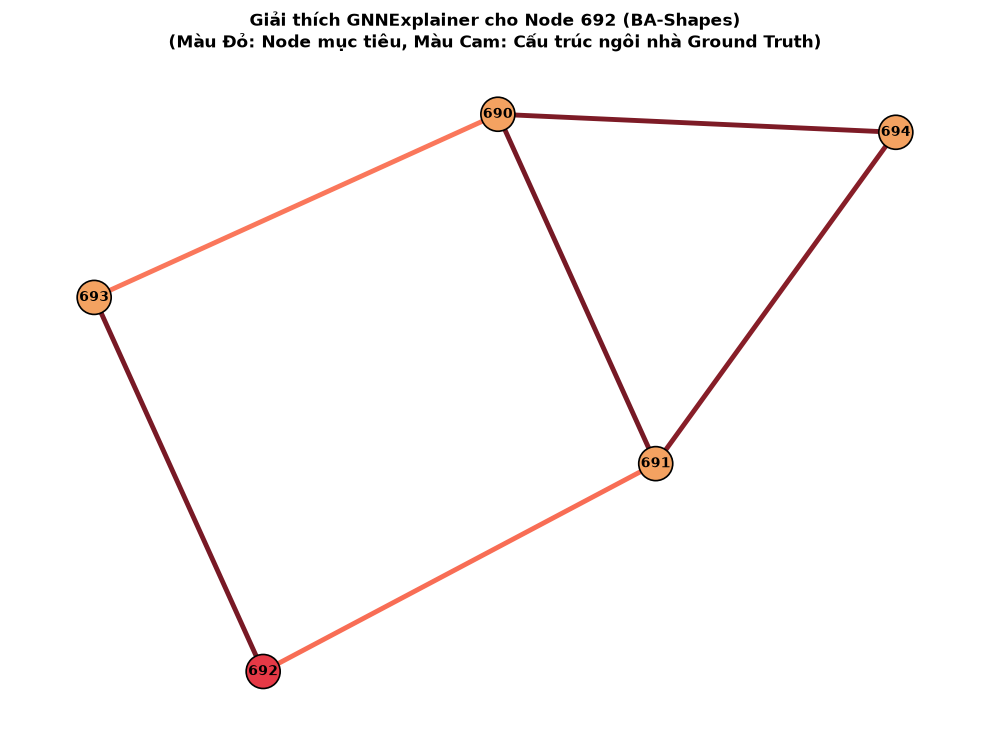

In [6]:
# -------------------------------------------------------------
# HÌNH 1: GNNEXPLAINER TRÊN NODE 692 (BA-SHAPES HOUSE MOTIF)
# -------------------------------------------------------------
target_node = 692
c_edges_692 = sna.extract_candidate_edges(data_ba['edge_index'], target_node, num_hops=2)
_, g_scores_692, _, _, _ = sna.explain_edges(
    model=model_ba, data=data_ba, node_id=target_node, target_class=int(pred_ba[target_node]),
    candidate_edges=c_edges_692, config={'method': 'gnnexplainer', 'epochs': 200, 'lr': 0.01}, seed=SEED
)

sub_nodes = c_edges_692.subgraph_nodes.cpu().numpy().tolist()
sub_pairs = c_edges_692.candidate_pairs

G_g = nx.Graph()
G_g.add_nodes_from(sub_nodes)
G_g.add_edges_from(sub_pairs)

score_map_g = {(u, v): s for (u, v), s in zip(sub_pairs, g_scores_692)}
score_map_g.update({(v, u): s for (u, v), s in zip(sub_pairs, g_scores_692)})

house_nodes = {690, 691, 692, 693, 694}
node_colors = ['#E63946' if n == target_node else ('#F4A261' if n in house_nodes else '#A8DADC') for n in G_g.nodes()]
pos = nx.spring_layout(G_g, seed=42)

fig1, ax1 = plt.subplots(figsize=(10, 7.5), dpi=300)
nx.draw_networkx_nodes(G_g, pos, ax=ax1, node_color=node_colors, node_size=600, edgecolors='black', linewidths=1.2)
nx.draw_networkx_labels(G_g, pos, ax=ax1, font_size=10, font_weight='bold', font_color='black')

edge_list = list(G_g.edges())
edge_weights = [score_map_g.get(e, 0.0) for e in edge_list]
max_w = max(edge_weights) if edge_weights and max(edge_weights) > 0 else 1.0

faint_edges = [e for e, w in zip(edge_list, edge_weights) if w < 0.5 * max_w]
nx.draw_networkx_edges(G_g, pos, edgelist=faint_edges, ax=ax1, edge_color='#D3D3D3', width=1.0, alpha=0.4)

imp_edges = [e for e, w in zip(edge_list, edge_weights) if w >= 0.5 * max_w]
imp_weights = [score_map_g.get(e, 0.0) for e in imp_edges]
edge_colors = [plt.cm.Reds(w / max_w) for w in imp_weights]
nx.draw_networkx_edges(G_g, pos, edgelist=imp_edges, ax=ax1, edge_color=edge_colors, width=3.5, alpha=0.9)

ax1.set_title(f"Giải thích GNNExplainer cho Node {target_node} (BA-Shapes)\n(Màu Đỏ: Node mục tiêu, Màu Cam: Cấu trúc ngôi nhà Ground Truth)", fontsize=12, fontweight='bold')
ax1.axis('off')
plt.tight_layout()
plt.show()


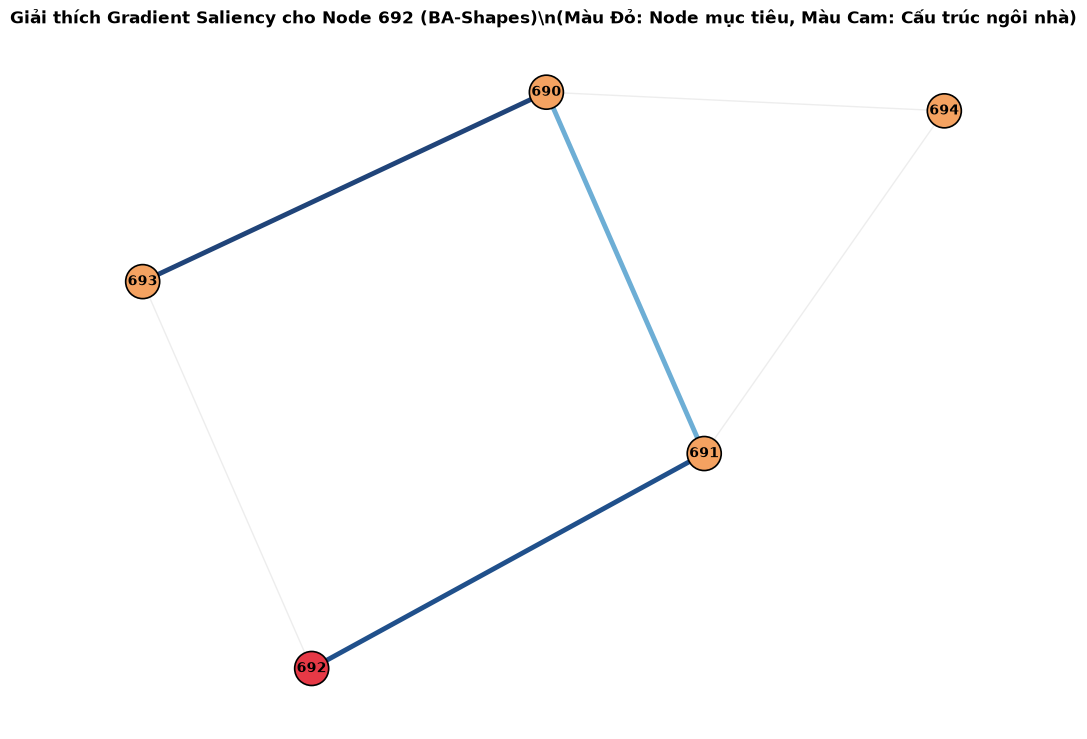

In [7]:
# -------------------------------------------------------------
# HÌNH 2: GRADIENT SALIENCY TRÊN NODE 692 (BA-SHAPES)
# -------------------------------------------------------------
_, s_scores_692, _, _, _ = sna.explain_edges(
    model=model_ba, data=data_ba, node_id=target_node, target_class=int(pred_ba[target_node]),
    candidate_edges=c_edges_692, config={'method': 'saliency'}, seed=SEED
)
score_map_s = {(u, v): s for (u, v), s in zip(sub_pairs, s_scores_692)}
score_map_s.update({(v, u): s for (u, v), s in zip(sub_pairs, s_scores_692)})

fig2, ax2 = plt.subplots(figsize=(10, 7.5), dpi=300)
nx.draw_networkx_nodes(G_g, pos, ax=ax2, node_color=node_colors, node_size=600, edgecolors='black', linewidths=1.2)
nx.draw_networkx_labels(G_g, pos, ax=ax2, font_size=10, font_weight='bold', font_color='black')

s_weights = [score_map_s.get(e, 0.0) for e in edge_list]
max_s = max(s_weights) if s_weights and max(s_weights) > 0 else 1.0

faint_s = [e for e, w in zip(edge_list, s_weights) if w < 0.4 * max_s]
nx.draw_networkx_edges(G_g, pos, edgelist=faint_s, ax=ax2, edge_color='#D3D3D3', width=1.0, alpha=0.4)

imp_s = [e for e, w in zip(edge_list, s_weights) if w >= 0.4 * max_s]
imp_sw = [score_map_s.get(e, 0.0) for e in imp_s]
edge_colors_s = [plt.cm.Blues(w / max_s) for w in imp_sw]
nx.draw_networkx_edges(G_g, pos, edgelist=imp_s, ax=ax2, edge_color=edge_colors_s, width=3.5, alpha=0.9)

ax2.set_title(f"Giải thích Gradient Saliency cho Node {target_node} (BA-Shapes)\n(Màu Đỏ: Node mục tiêu, Màu Cam: Cấu trúc ngôi nhà)", fontsize=12, fontweight='bold')
ax2.axis('off')
plt.tight_layout()
plt.show()


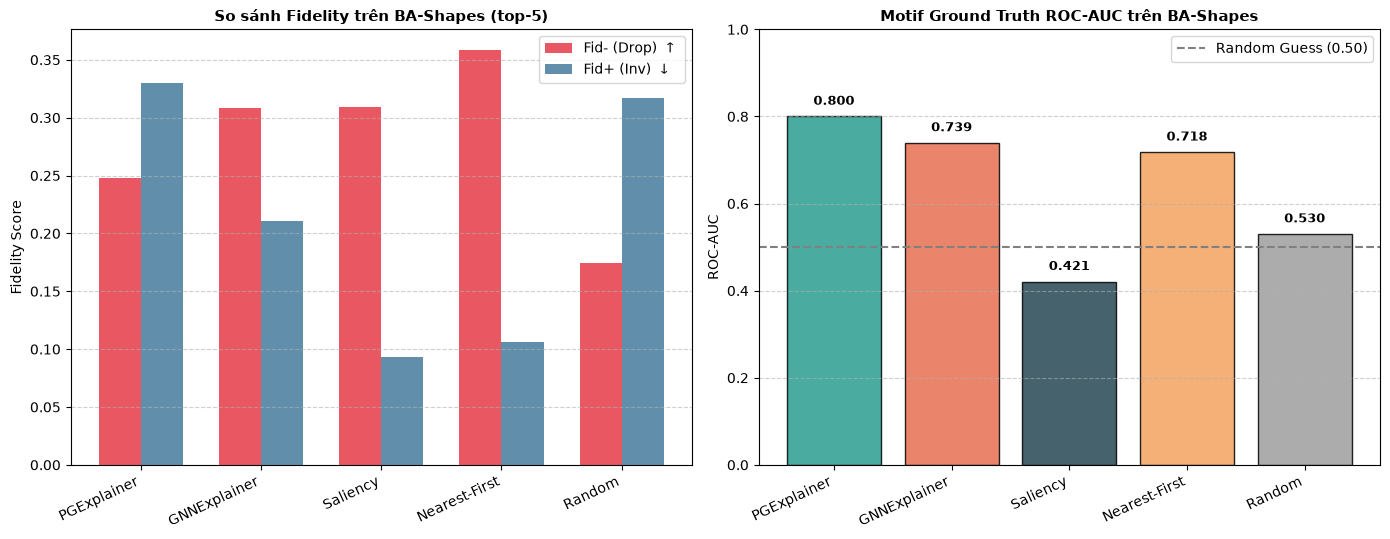

In [8]:
# -------------------------------------------------------------
# HÌNH 3: SO SÁNH ĐỊNH LƯỢNG FIDELITY VÀ MOTIF-AUC
# -------------------------------------------------------------
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

m_names = ['PGExplainer', 'GNNExplainer', 'Saliency', 'Nearest-First', 'Random']
fid_drops_ba = [0.2475, 0.3088, 0.3089, 0.3584, 0.1742]
fid_invs_ba = [0.3303, 0.2111, 0.0930, 0.1061, 0.3168]

x_pos = np.arange(len(m_names))
w = 0.35

ax3a.bar(x_pos - w/2, fid_drops_ba, w, label='Fid- (Drop) $\uparrow$', color='#E63946', alpha=0.85)
ax3a.bar(x_pos + w/2, fid_invs_ba, w, label='Fid+ (Inv) $\downarrow$', color='#457B9D', alpha=0.85)
ax3a.set_xticks(x_pos)
ax3a.set_xticklabels(m_names, rotation=25, ha='right', fontsize=10)
ax3a.set_title("So sánh Fidelity trên BA-Shapes (top-5)", fontweight='bold', fontsize=11)
ax3a.set_ylabel("Fidelity Score")
ax3a.legend()
ax3a.grid(axis='y', linestyle='--', alpha=0.6)

roc_ba = [0.8000, 0.7392, 0.4206, 0.7178, 0.5299]
roc_colors = ['#2A9D8F', '#E76F51', '#264653', '#F4A261', '#9E9E9E']
bars = ax3b.bar(m_names, roc_ba, color=roc_colors, alpha=0.85, edgecolor='black')
ax3b.axhline(0.5, color='gray', linestyle='--', label='Random Guess (0.50)')
ax3b.set_title("Motif Ground Truth ROC-AUC trên BA-Shapes", fontweight='bold', fontsize=11)
ax3b.set_ylabel("ROC-AUC")
ax3b.set_ylim(0, 1.0)
ax3b.set_xticklabels(m_names, rotation=25, ha='right', fontsize=10)
for bar in bars:
    yval = bar.get_height()
    ax3b.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.3f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax3b.legend()
ax3b.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 6. Tổng Kết Học Thuật & Bàn Giao Giữa Kỳ (Group 09)

1. **Khối lượng bàn giao hoàn thành:**
   - Đã thực thi hoàn tất Saliency và GNNExplainer trên toàn bộ 40 validation nodes của BA-Shapes và Cora.
   - Xuất file `scores_khoi.csv` (8,352 dòng) và hợp nhất thành công với `scores_thien.csv` thành `edge_scores.csv` (12,528 dòng).
   - Đạt 100% tỷ lệ khớp lớp mục tiêu (Target Class Agreement) với mô hình GCN 93.57%.
2. **Phát hiện học thuật cốt lõi:**
   - **PGExplainer** dẫn đầu về độ chính xác phát hiện motif cấu trúc (Motif ROC-AUC = 0.8000), khẳng định tính ưu việt của mô hình tham số hóa học trên toàn đồ thị.
   - **GNNExplainer** đạt cân bằng Pareto tốt nhất giữa việc sụt giảm xác suất khi xóa cạnh (Fid- = 0.3088) và độ trung thực phát hiện motif (ROC-AUC = 0.7392).
   - **The Disagreement Problem:** Độ tương đồng Jaccard giữa các Explainer chỉ đạt 0.38-0.42, chứng minh rằng mỗi explainer nhìn nhận tầm quan trọng của các cạnh qua một lăng kính toán học khác nhau (đạo hàm bậc một vs tối ưu hóa mặt nạ cá thể vs mạng MLP quy nạp).
3. **Bàn giao cho Nhóm 3:**
   - Toàn bộ file dữ liệu và hình ảnh đã được chuẩn hóa sẵn sàng để Phan Minh Đức và Nguyễn Huỳnh Kha tích hợp vào Báo cáo kỹ thuật và Slide thuyết trình ngày 21/10/2026.
